# Tema 10 · Preparar datos: limpieza, variables y pipelines

La mayor parte del trabajo real: dejar los datos listos sin hacerse trampa.

Este cuaderno es el tema 10 de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/ruta/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/ruta/10-preparar-datos-limpieza-variables-y-pipelines/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

# Teoría

## La pregunta

En el tema 4 exploraste la lista de pasajeros del Titanic: quién viajaba en qué clase, cuántos sobrevivieron, a quién le falta la edad. Ahora queremos ir un paso más allá y entrenar un modelo que, a partir de los datos de un pasajero, prediga si sobrevivió.

Ya conoces modelos que sirven para eso, como los vecinos cercanos y la regresión logística del tema 8. Pero si intentas darle la tabla tal cual a `fit`, no funciona: a 177 pasajeros les falta la edad, el sexo está escrito como texto (`"male"`, `"female"`) y la tarifa va de 0 a más de 500 mientras que el número de hermanos va de 0 a 8. Antes de entrenar hay que **preparar los datos**, y en los proyectos reales eso suele llevar más tiempo que elegir el modelo.

Hay una segunda dificultad, más traicionera: es muy fácil preparar los datos de una forma que **hace trampa sin que te des cuenta**, y que te muestra un modelo mucho mejor de lo que es. A eso se le llama **fuga de datos**, y aprender a evitarla es lo más importante de este tema.

En este tema vas a:

- **imputar** valores faltantes con la media o la mediana, y justificar cuál elegir;
- convertir variables de texto en números con **one-hot**, y **escalar** las numéricas (estandarizar y normalizar);
- reconocer la **fuga de datos** y evitarla con un `Pipeline` y un `ColumnTransformer`;
- buscar **hiperparámetros** con `GridSearchCV` y `RandomizedSearchCV`;
- crear **variables nuevas** y medir si de verdad ayudan.

Necesitas lo del tema 4 (pandas), el puntaje z del tema 5, la división en entrenamiento y prueba y la validación cruzada del tema 7, los vecinos cercanos y la regresión logística del tema 8, y la exactitud y las métricas del tema 9.

## Actividad: la escala importa

Los vecinos cercanos deciden por **distancia**: el ejemplo nuevo se parece a los que tiene más cerca. Pero ¿cerca en qué unidades? Aquí hay 40 personas inventadas (datos sintéticos) con dos variables: su **ingreso mensual en bolivianos** y su **edad en años**. El punto coral es una persona nueva, y los anillos marcan sus 5 vecinos más cercanos.

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/ruta/10-preparar-datos-limpieza-variables-y-pipelines/teoria/). Ábrela en el navegador para usarla.
Prueba esto, en orden:

1. Sin estandarizar, mira la lista de vecinos. ¿En qué se parecen entre sí? ¿Y en qué no se parecen nada?
2. Fíjate en la forma de la zona sombreada alrededor del punto coral. ¿Por qué es una franja tan angosta y alta?
3. Activa «Estandarizar». La nube casi no se mueve, pero los ejes cambian de unidades. ¿Qué pasa con los vecinos y con la zona?
4. Mueve el punto coral (tocando el gráfico o con las flechas del teclado) a una persona de 60 años y compara los vecinos con y sin estandarizar.

Sin estandarizar, una diferencia de 1000 bolivianos pesa lo mismo que una diferencia de 1000 años. Como las edades solo varían unas decenas, la edad casi no cuenta y los vecinos son simplemente las personas con ingreso parecido. **Sin escalar, la variable con números grandes manda.** Al estandarizar, cada variable se mide en desviaciones estándar y las dos pesan parecido.

## Los datos tal como llegan

Cargamos el Titanic como en el tema 4 y miramos unas filas:

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

titanic = sns.load_dataset("titanic")
print(titanic.shape)
print(titanic[["survived", "pclass", "sex", "age", "fare",
               "embarked", "deck"]].head())

(891, 15)
   survived  pclass     sex   age     fare embarked deck
0         0       3    male  22.0   7.2500        S  NaN
1         1       1  female  38.0  71.2833        C    C
2         1       3  female  26.0   7.9250        S  NaN
3         1       1  female  35.0  53.1000        S    C
4         0       3    male  35.0   8.0500        S  NaN


Cada fila es un pasajero. `survived` es la respuesta (1 si sobrevivió), `pclass` la clase del pasaje (1, 2 o 3), `age` la edad, `sibsp` cuántos hermanos o pareja viajaban con él, `parch` cuántos padres o hijos, `fare` la tarifa que pagó, `embarked` el puerto donde subió (S, C o Q) y `deck` la cubierta de su camarote.

El primer paso de cualquier preparación es saber **qué falta y dónde**. Un mapa de faltantes pinta de oscuro cada casilla vacía: una fila de píxeles por pasajero y una columna por variable.

survived     0.0
pclass       0.0
sex          0.0
age         19.9
sibsp        0.0
parch        0.0
fare         0.0
embarked     0.2
deck        77.2
dtype: float64


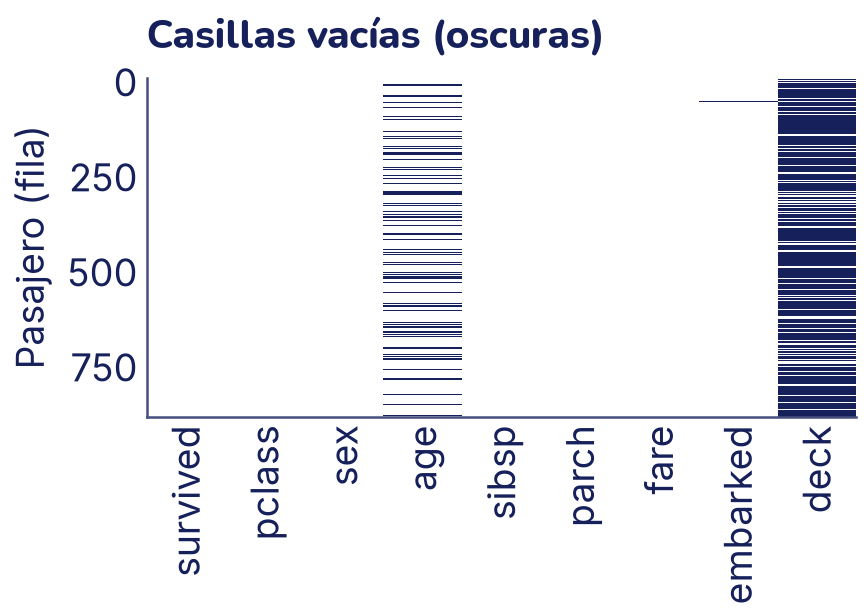

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

cols = ["survived", "pclass", "sex", "age", "sibsp", "parch",
        "fare", "embarked", "deck"]
faltan = titanic[cols].isna()
print((faltan.mean() * 100).round(1))

blanco_tinta = LinearSegmentedColormap.from_list("bt", ["white", "C0"])
plt.imshow(faltan, aspect="auto", cmap=blanco_tinta,
           interpolation="nearest")
plt.xticks(range(len(cols)), cols, rotation=90)
plt.grid(False)                       # sin rejilla encima del mapa
plt.ylabel("Pasajero (fila)")
plt.title("Casillas vacías (oscuras)")
plt.show()

Tres columnas tienen huecos: a `deck` le falta el 77 % (casi todo), a `age` el 20 % y a `embarked` solo dos pasajeros. Con `deck` no hay mucho que rescatar, así que la dejamos fuera. Las otras dos las vamos a **rellenar**.

El dataset de seaborn trae además columnas que son copias o resúmenes de otras: `class` repite `pclass`, `embark_town` repite `embarked`, `who` y `adult_male` salen de la edad y el sexo, y `alive` es `survived` escrito con palabras (`"yes"` o `"no"`). Esa última es peligrosa: si la usaras como entrada, el modelo acertaría siempre, porque le estarías dando la respuesta. Es la forma más burda de fuga de datos, y la vas a cazar en los ejercicios. Nos quedamos con siete columnas:

In [ ]:
columnas = ["pclass", "sex", "age", "sibsp", "parch", "fare",
            "embarked"]
X = titanic[columnas]
y = titanic["survived"]
print(X.shape, "  sobrevivió:", round(y.mean() * 100, 1), "%")

(891, 7)   sobrevivió: 38.4 %


## Primero, dividir

Antes de tocar un solo dato, separamos el conjunto de **prueba**, como en el tema 7. La prueba hace de «examen final»: representa a los pasajeros que el modelo nunca vio. Todo lo que aprendamos (cuál es la edad típica, cuánto varía la tarifa, qué modelo conviene) lo vamos a aprender **solo del entrenamiento**.

In [ ]:
from sklearn.model_selection import train_test_split

# stratify=y: la misma proporción de sobrevivientes en las dos partes
X_ent, X_prueba, y_ent, y_prueba = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=0)
print("Entrenamiento:", X_ent.shape, "  prueba:", X_prueba.shape)
print("Edades faltantes:", X_ent["age"].isna().sum(), "y",
      X_prueba["age"].isna().sum())

Entrenamiento: (668, 7)   prueba: (223, 7)
Edades faltantes: 136 y 41


Esta regla, **dividir primero y preparar después**, parece un detalle. Más abajo vas a ver con números por qué no lo es.

## Valores faltantes

Un dato puede faltar por razones muy distintas, y la razón importa:

- **Falta al azar**: se perdió una hoja, alguien se olvidó de anotar. Que falte no dice nada del pasajero.
- **Falta por algo que sí vemos**: por ejemplo, si a los de tercera clase se les anotó la edad con menos cuidado. Que falte depende de otra columna.
- **Falta por el propio valor**: por ejemplo, si las personas con ingresos muy altos prefieren no decir su ingreso. Es el caso más difícil, porque los que faltan son distintos de los que están.

Hay dos salidas. **Borrar** las filas incompletas (`dropna`, como en el tema 4) es simple, pero aquí tiraría el 20 % de los pasajeros, y cuando llegue un pasajero nuevo sin edad el modelo no sabría qué hacer con él. **Imputar** es rellenar el hueco con un valor razonable, casi siempre la media o la mediana de la columna. ¿Cuál de las dos?

In [ ]:
for col in ["age", "fare"]:
    print(f"{col}:  media = {X_ent[col].mean():5.2f}"
          f"   mediana = {X_ent[col].median():5.2f}"
          f"   máximo = {X_ent[col].max():6.2f}")

age:  media = 29.80   mediana = 29.00   máximo =  80.00
fare:  media = 33.27   mediana = 14.45   máximo = 512.33


En la edad, la media y la mediana casi coinciden: la distribución es bastante simétrica y cualquiera de las dos sirve. En la tarifa no: unos pocos pasajes carísimos (más de 500) tiran la media hacia arriba, hasta más del doble de la mediana. La media de la tarifa no describe a un pasajero típico; la mediana, sí. Por eso la regla práctica es: **mediana si la columna es asimétrica (con una cola larga hacia un lado, como la tarifa) o tiene atípicos, media si es simétrica**. La mediana casi nunca sale muy mal, así que es la opción por defecto más segura.

Para las columnas de texto no hay media ni mediana: se rellena con el valor **más frecuente** (la moda).

scikit-learn lo hace con `SimpleImputer`. Funciona como un modelo: `fit` **aprende** el valor de relleno (aquí, la mediana del entrenamiento) y `transform` lo **aplica**, a los datos que sea:

In [ ]:
from sklearn.impute import SimpleImputer

imputar_edad = SimpleImputer(strategy="median")
imputar_edad.fit(X_ent[["age"]])      # aprende con el entrenamiento
print("Mediana aprendida:", imputar_edad.statistics_)

edad_ent = imputar_edad.transform(X_ent[["age"]])
edad_prueba = imputar_edad.transform(X_prueba[["age"]])
print("Faltantes después:", np.isnan(edad_ent).sum(), "y",
      np.isnan(edad_prueba).sum())

imputar_puerto = SimpleImputer(strategy="most_frequent")
imputar_puerto.fit(X_ent[["embarked"]])
print("Puerto más frecuente:", imputar_puerto.statistics_)

Mediana aprendida: [29.]
Faltantes después: 0 y 0
Puerto más frecuente: ['S']


Fíjate en que la prueba se rellena con la mediana **del entrenamiento**, no con la suya. Es lo que va a pasar cuando el modelo esté en uso: llega un pasajero nuevo sin edad y lo único que conocemos es lo que aprendimos antes.

Imputar tiene un costo: 136 pasajeros del entrenamiento quedan con exactamente la misma edad, 29 años, y la columna se vuelve un poco más «picuda» de lo que era. Si sospechas que el hecho de que falte dice algo, puedes guardar esa información en una columna aparte con `SimpleImputer(add_indicator=True)`, que agrega una columna con 1 donde el dato faltaba.

## Variables categóricas: one-hot

Los modelos solo entienden números. ¿Cómo convertimos el puerto `embarked`, que vale S, C o Q? La idea ingenua es numerarlos: S = 0, C = 1, Q = 2. Pero así le estás diciendo al modelo que Q es «el doble» de C y que C está «entre» S y Q. Para los vecinos cercanos, Southampton quedaría más cerca de Cherburgo que de Queenstown solo por cómo los numeraste. Los puertos no tienen orden: son una variable **nominal**.

La solución es **one-hot** (uno caliente): una columna por cada valor posible, con un 1 en la que corresponde y 0 en las demás.

In [ ]:
from sklearn.preprocessing import OneHotEncoder

puertos = pd.DataFrame({"embarked": ["S", "C", "Q", "S"]})
onehot = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
onehot.fit(puertos)
print(onehot.get_feature_names_out())
print(onehot.transform(puertos))
# Un puerto que no apareció en el entrenamiento queda todo en cero
nuevo = pd.DataFrame({"embarked": ["X"]})
print(onehot.transform(nuevo))

['embarked_C' 'embarked_Q' 'embarked_S']
[[0. 0. 1.]
 [1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
[[0. 0. 0.]]


Ahora los tres puertos están a la misma distancia entre sí. `handle_unknown="ignore"` evita un error cuando, ya en uso, aparece un valor que no estaba en el entrenamiento.

¿Y la clase del pasaje, `pclass`? Ahí sí hay un orden: primera es «más» que segunda, y segunda más que tercera. Una variable así se llama **ordinal**, y muchas veces se puede dejar como número. Es lo que vamos a hacer. El sexo tiene dos valores; one-hot lo convierte en dos columnas que dicen lo mismo, y eso no le hace daño a ningún modelo de este tema.

## Escalar: estandarizar y normalizar

La actividad mostró el problema: las distancias, y también el descenso de gradiente del tema 6, se dejan llevar por las columnas con números grandes. Hay dos formas comunes de poner todas las columnas en una escala parecida.

**Estandarizar** es lo que hiciste en el tema 5 con el puntaje z: restar la media y dividir por la desviación estándar. Cada columna queda con media 0 y desviación 1.

$${x}_{\text{est}} = \frac{x - \text{media}}{\text{desviación}}$$

**Normalizar** (o escalar al rango) lleva el mínimo a 0 y el máximo a 1:

$${x}_{\text{norm}} = \frac{x - \text{mín}}{\text{máx} - \text{mín}}$$

En scikit-learn son `StandardScaler` y `MinMaxScaler`, y funcionan igual que el imputador: `fit` aprende la media y la desviación (o el mínimo y el máximo) **del entrenamiento**, y `transform` las aplica.

Medias: [29.63 33.27]
Desviaciones: [12.91 53.43]
Estandarizadas: de [-2.26 -0.62] a [3.9  8.97]
Normalizadas:   de [0. 0.] a [1. 1.]


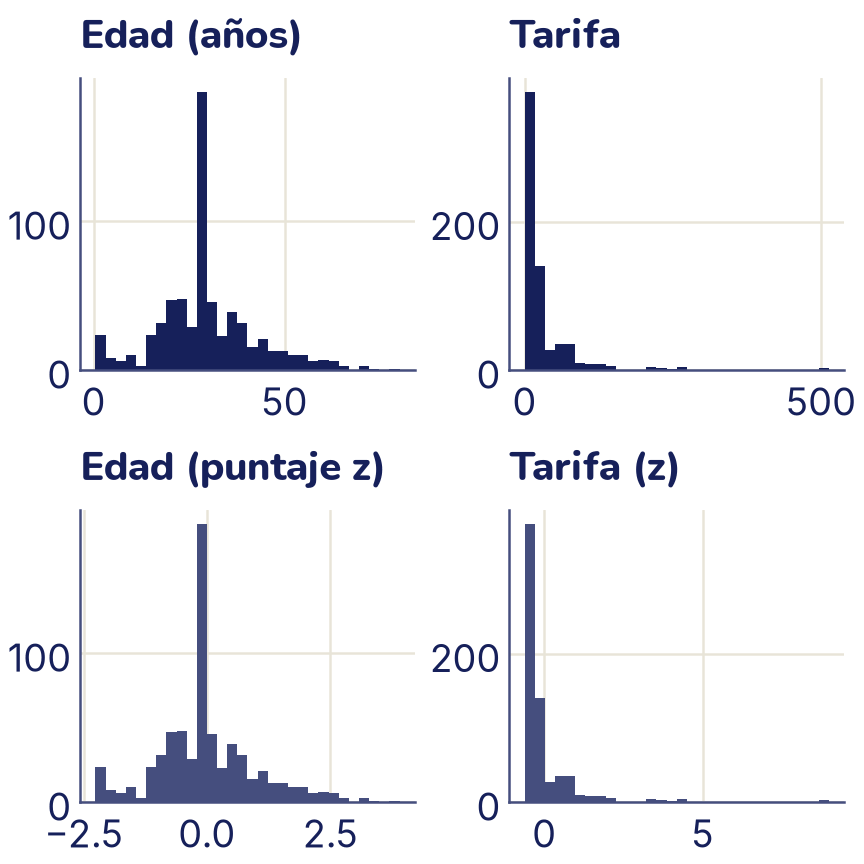

In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Primero rellenamos la edad; la tarifa no tiene faltantes
edad_tarifa = pd.DataFrame(
    {"edad": edad_ent[:, 0], "tarifa": X_ent["fare"].to_numpy()})

estandarizar = StandardScaler().fit(edad_tarifa)
print("Medias:", estandarizar.mean_.round(2))
print("Desviaciones:", estandarizar.scale_.round(2))
est = estandarizar.transform(edad_tarifa)

normalizar = MinMaxScaler().fit(edad_tarifa)
norm = normalizar.transform(edad_tarifa)
print("Estandarizadas: de", est.min(axis=0).round(2),
      "a", est.max(axis=0).round(2))
print("Normalizadas:   de", norm.min(axis=0).round(2),
      "a", norm.max(axis=0).round(2))

fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8))
ejes[0, 0].hist(edad_tarifa["edad"], bins=30)
ejes[0, 0].set_title("Edad (años)")
ejes[0, 1].hist(edad_tarifa["tarifa"], bins=30)
ejes[0, 1].set_title("Tarifa")
ejes[1, 0].hist(est[:, 0], bins=30, color="C2")
ejes[1, 0].set_title("Edad (puntaje z)")
ejes[1, 1].hist(est[:, 1], bins=30, color="C2")
ejes[1, 1].set_title("Tarifa (z)")
plt.show()

Compara la fila de arriba con la de abajo: **las formas son idénticas**. Escalar no cambia la distribución, solo las unidades del eje (es estirar y correr la regla). La tarifa estandarizada sigue teniendo su cola larga, con valores de casi 9 desviaciones sobre la media. Por eso la normalización al rango sufre con los atípicos: un solo pasaje de 512 se vuelve el 1, y casi todos los demás quedan apretados cerca de 0.

¿Cuál usar? La estandarización es la opción por defecto y es la que suponen la regresión logística regularizada y el descenso de gradiente. La normalización al rango sirve cuando necesitas valores entre 0 y 1 (por ejemplo, los píxeles de una imagen). Con atípicos fuertes, la estandarización sufre menos que la normalización al rango, pero tampoco es ideal: la media y la desviación estándar también se dejan arrastrar por ellos (por eso la tarifa estandarizada llega a casi 9). Para esos casos existe `RobustScaler`, que usa la mediana y el rango intercuartílico (RIC) del tema 4. Y algunos modelos, como los árboles del tema 11, no necesitan escalar nada.

## Fuga de datos

Hay **fuga de datos** cuando, al entrenar o preparar el modelo, se cuela información que en la vida real no vas a tener en el momento de predecir. La forma más común es usar los datos de prueba (o de validación) para preparar los datos. El modelo se evalúa con un examen cuyas preguntas ya vio de reojo, y el puntaje sale mejor de lo que es.

Mira qué pasa si imputamos y escalamos con **todos** los pasajeros, antes de dividir:

In [ ]:
# Con fuga: las cuentas usan también a los pasajeros de prueba
print(f"Mediana de la edad:  todos = {X['age'].median()}"
      f"   solo entrenamiento = {X_ent['age'].median()}")
print(f"Media de la tarifa:  todos = {X['fare'].mean():.2f}"
      f"   solo entrenamiento = {X_ent['fare'].mean():.2f}")

Mediana de la edad:  todos = 28.0   solo entrenamiento = 29.0
Media de la tarifa:  todos = 32.20   solo entrenamiento = 33.27


Las cifras cambian: si preparas con todos, la mediana con que rellenas y la media con que escalas ya «saben» algo de los pasajeros de prueba. Con 891 pasajeros y pasos tan simples como una mediana, el cambio es chico, y más abajo vas a ver que aquí el puntaje casi no se mueve. Pero el error de fondo es el mismo que puede arruinar un proyecto entero. Para verlo en grande, hagamos un experimento con datos **sintéticos** donde no hay nada que aprender.

Inventamos 200 ejemplos con 5000 columnas de números al azar y una respuesta, 0 o 1, también al azar. Ninguna columna tiene relación con la respuesta, así que ningún modelo honesto puede acertar más que tirando una moneda: alrededor del 50 %. Antes de entrenar, hacemos un paso de preparación muy común: **quedarnos con las 20 columnas más relacionadas con la respuesta** (`SelectKBest`). En una versión elegimos las columnas con los 200 ejemplos y después dividimos; en la otra, dividimos primero y elegimos solo con el entrenamiento. Además, generamos 1000 ejemplos nuevos para ver cómo le va de verdad a cada modelo.

Con fuga:  prueba = 0.80   datos nuevos = 0.487
Sin fuga:  prueba = 0.56   datos nuevos = 0.515


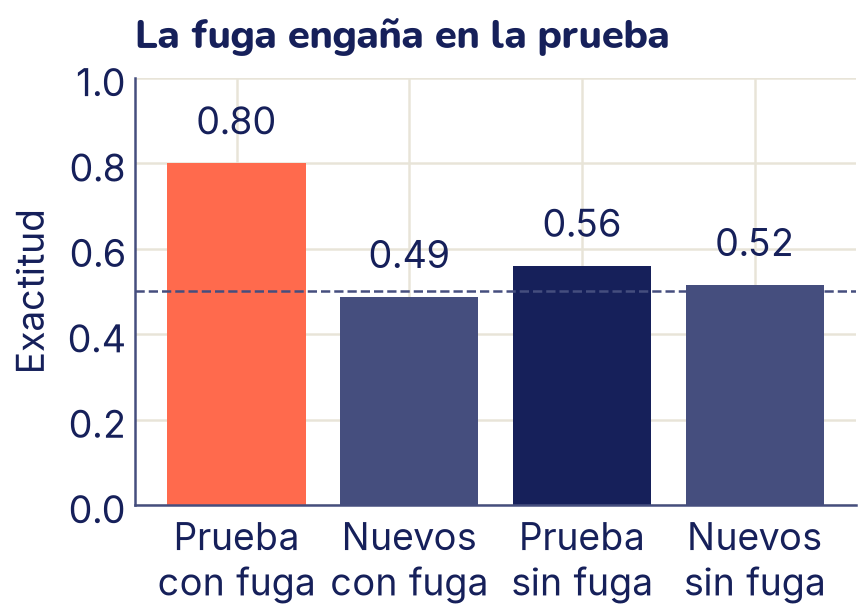

In [ ]:
from sklearn.feature_selection import SelectKBest
from sklearn.linear_model import LogisticRegression

rng = np.random.default_rng(0)
X_azar = rng.normal(size=(200, 5000))     # 5000 columnas de ruido
y_azar = rng.integers(0, 2, size=200)     # respuestas al azar
X_nuevo = rng.normal(size=(1000, 5000))   # datos que llegan después
y_nuevo = rng.integers(0, 2, size=1000)

Xa_ent, Xa_prueba, ya_ent, ya_prueba = train_test_split(
    X_azar, y_azar, test_size=0.25, random_state=0)

resultados = {}
for nombre, Xs, ys in [("Con fuga", X_azar, y_azar),
                       ("Sin fuga", Xa_ent, ya_ent)]:
    # La única diferencia: con qué filas se eligen las 20 columnas
    elegir = SelectKBest(k=20).fit(Xs, ys)
    modelo = LogisticRegression().fit(elegir.transform(Xa_ent), ya_ent)
    resultados[nombre] = [
        modelo.score(elegir.transform(Xa_prueba), ya_prueba),
        modelo.score(elegir.transform(X_nuevo), y_nuevo)]
    print(f"{nombre}:  prueba = {resultados[nombre][0]:.2f}"
          f"   datos nuevos = {resultados[nombre][1]:.3f}")

alturas = resultados["Con fuga"] + resultados["Sin fuga"]
nombres = ["Prueba\ncon fuga", "Nuevos\ncon fuga",
           "Prueba\nsin fuga", "Nuevos\nsin fuga"]
# Coral solo para el número engañoso
barras = plt.bar(nombres, alturas, color=["C1", "C2", "C0", "C2"])
# padding separa los números de la línea punteada del 0,5
plt.bar_label(barras, fmt="%.2f", padding=8)
plt.axhline(0.5, color="C2", linestyle="--", linewidth=1)
plt.ylim(0, 1)
plt.ylabel("Exactitud")
plt.title("La fuga engaña en la prueba")
plt.show()

Con fuga, la prueba dice que el modelo acierta el **80 %** de las veces con datos que son puro ruido. Es mentira: con los 1000 ejemplos nuevos acierta el 49 %, lo mismo que una moneda. Lo que pasó es que, entre 5000 columnas al azar, siempre hay algunas que por pura casualidad se parecen a la respuesta **en esos 200 ejemplos**, incluidos los 50 de prueba. Al elegirlas mirando también la prueba, elegimos justo las casualidades que hacen quedar bien al modelo en ese examen. Sin fuga, la prueba da un 56 %, cerca del azar, que es la verdad: no hay nada que aprender.

La lección general: **todo paso que aprende algo de los datos (imputar, escalar, elegir columnas, codificar) es parte del modelo y se ajusta solo con el entrenamiento**. Esto vale para la división en entrenamiento y prueba, y también para cada pliegue de la validación cruzada del tema 7. Hacerlo a mano en cada pliegue es tedioso y fácil de olvidar. Para eso existe el `Pipeline`.

## Pipeline y ColumnTransformer

Un **`Pipeline`** (tubería) encadena pasos: cada uno le pasa su resultado al siguiente, y el último es el modelo. Lo importante es que se comporta como **un solo modelo**: cuando llamas a `fit`, ajusta cada paso solo con los datos que le das; cuando llamas a `predict` o `score`, aplica lo que aprendió. Así, la validación cruzada y la búsqueda de hiperparámetros reciben el pipeline completo y lo reentrenan entero en cada pliegue, sin fuga.

Nuestras columnas necesitan tratamientos distintos: las numéricas, imputar con la mediana y estandarizar; las de texto, imputar con la más frecuente y pasar a one-hot. Un **`ColumnTransformer`** aplica a cada grupo de columnas su propio tratamiento y junta los resultados en una sola tabla.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

numericas = ["pclass", "age", "sibsp", "parch", "fare"]
categoricas = ["sex", "embarked"]

prep_numericas = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", StandardScaler())])
prep_categoricas = Pipeline([
    ("imputar", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preparar = ColumnTransformer([
    ("num", prep_numericas, numericas),
    ("cat", prep_categoricas, categoricas)])

pipe_knn = Pipeline([("preparar", preparar),
                     ("modelo", KNeighborsClassifier(n_neighbors=5))])
pipe_knn.fit(X_ent, y_ent)

print(pipe_knn.named_steps["preparar"].get_feature_names_out())
print("Forma lista para el modelo:",
      pipe_knn.named_steps["preparar"].transform(X_ent).shape)

['num__pclass' 'num__age' 'num__sibsp' 'num__parch' 'num__fare'
 'cat__sex_female' 'cat__sex_male' 'cat__embarked_C' 'cat__embarked_Q'
 'cat__embarked_S']
Forma lista para el modelo: (668, 10)


Las 7 columnas originales se convirtieron en 10: las 5 numéricas (con su prefijo `num__`) y 5 de one-hot (dos para el sexo, tres para el puerto). Cada paso tiene un nombre, y los nombres forman un árbol:

```text
pipe_knn
├── preparar   (ColumnTransformer)
│   ├── num    (Pipeline)
│   │   ├── imputar
│   │   └── escalar
│   └── cat    (Pipeline)
│       ├── imputar
│       └── onehot
└── modelo     (KNeighborsClassifier)
```

Hay dos formas de llegar a una pieza. `pipe_knn.named_steps["preparar"]` devuelve el paso `preparar`, como en un diccionario. Y para nombrar algo que está más adentro se escribe el camino del árbol, uniendo los nombres con doble guion bajo: `preparar__num__escalar` es «el paso `escalar`, dentro de `num`, dentro de `preparar`».

Ahora la validación cruzada del tema 7 recibe el pipeline completo. Comparemos los vecinos cercanos con la estandarización y sin ella. El código usa dos herramientas nuevas:

- `clone(pipe_knn)` hace una copia sin entrenar del pipeline, para no tocar el original.
- `.set_params(preparar__num__escalar=escala)` reemplaza el paso que está en ese camino. El valor `"passthrough"` significa «no hacer nada»: el paso deja pasar los datos sin cambiarlos.

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_score

pliegues = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

for escala in [StandardScaler(), "passthrough"]:
    pipe = clone(pipe_knn).set_params(preparar__num__escalar=escala)
    puntajes = cross_val_score(pipe, X_ent, y_ent, cv=pliegues)
    print(f"Escalar = {str(escala):16}  exactitud = "
          f"{puntajes.mean():.3f} ± {puntajes.std():.3f}")

Escalar = StandardScaler()  exactitud = 0.808 ± 0.023
Escalar = passthrough       exactitud = 0.713 ± 0.026


Es la actividad con datos reales: sin escalar, la tarifa (que llega a 512) domina las distancias y los vecinos se eligen casi solo por lo que pagaron. Escalando, la exactitud sube casi 10 puntos.

¿Y la fuga del Titanic, la de imputar y escalar antes de dividir? Medimos lo mismo de dos formas: preparando una sola vez con todo el entrenamiento y después haciendo la validación cruzada (con fuga hacia cada pliegue de validación), o con el pipeline (sin fuga).

In [ ]:
# Con fuga: se prepara una vez con todas las filas del entrenamiento
X_preparado = clone(preparar).fit_transform(X_ent)
con_fuga = cross_val_score(KNeighborsClassifier(n_neighbors=5),
                           X_preparado, y_ent, cv=pliegues)
sin_fuga = cross_val_score(pipe_knn, X_ent, y_ent, cv=pliegues)
print(f"Con fuga: {con_fuga.mean():.3f}"
      f"   sin fuga: {sin_fuga.mean():.3f}")

Con fuga: 0.807   sin fuga: 0.808


Aquí la diferencia es mínima: una mediana o una media calculadas con 534 pasajeros o con 668 casi no cambian, así que la fuga no alcanza a inflar el puntaje. Con pocos datos, o con pasos que miran la respuesta (como elegir columnas), la diferencia es enorme, como viste con los datos al azar. El pipeline te protege en todos los casos sin que tengas que pensar en cuál estás.

## Crear variables nuevas

A veces la información está en los datos, pero no en una forma que el modelo pueda aprovechar. **Ingeniería de variables** es crear columnas nuevas a partir de las que hay. Algunas ideas típicas:

- **Conteos**: cuántas personas viajaban juntas, `familia = sibsp + parch + 1`.
- **Cocientes**: la tarifa del Titanic se pagaba por pasaje, que a veces cubría a toda una familia; `tarifa_persona = fare / familia` se acerca más a lo que pagó cada uno.
- **Umbrales**: la regresión logística trata la edad como una recta, pero en el tema 4 viste que los menores de 12 años sobrevivieron mucho más. `es_nino` vale 1 si la edad es menor que 12. (Si falta la edad, queda en 0.)
- **Resúmenes estadísticos**: cuando una fila tiene muchas medidas del mismo tipo (por ejemplo, cien lecturas de un sensor), se resumen con unos pocos números, como su media, su desviación estándar, su máximo o su asimetría. La **asimetría** mide hacia qué lado está la cola larga de los valores: es positiva si la cola va hacia la derecha (unos pocos valores muy grandes, como en la tarifa), negativa si va hacia la izquierda y cercana a 0 si los valores están repartidos parejo a los dos lados de la media. Lo vas a practicar en los ejercicios.

Estas variables se calculan **con los datos de cada fila**, sin mirar a los demás pasajeros, así que se pueden crear antes de dividir sin fuga. Una variable que usara a otros pasajeros (por ejemplo, «tarifa comparada con la media de su clase») sí tendría que aprenderse solo con el entrenamiento.

In [ ]:
def agregar_variables(df):
    """Agrega variables nuevas calculadas fila por fila."""
    df = df.copy()
    df["familia"] = df["sibsp"] + df["parch"] + 1
    df["tarifa_persona"] = df["fare"] / df["familia"]
    df["es_nino"] = (df["age"] < 12).astype(int)
    return df

X_ent_mas = agregar_variables(X_ent)
print(X_ent_mas[["sibsp", "parch", "familia", "fare",
                 "tarifa_persona", "age", "es_nino"]].head(4))

     sibsp  parch  familia  fare  tarifa_persona   age  es_nino
671      1      0        2  52.0       26.000000  31.0        0
417      0      2        3  13.0        4.333333  18.0        0
634      3      2        6  27.9        4.650000   9.0        1
323      1      1        3  29.0        9.666667  22.0        0


¿Ayudan? No basta con que suenen bien: hay que **medirlo**, con validación cruzada y solo con el entrenamiento. Comparamos una regresión logística con las columnas originales y con cada grupo de variables nuevas.

In [ ]:
def pipe_logistica(numericas):
    """Pipeline de regresión logística para unas columnas numéricas."""
    prep = ColumnTransformer([
        ("num", prep_numericas, numericas),
        ("cat", prep_categoricas, categoricas)])
    return Pipeline([("preparar", prep),
                     ("modelo", LogisticRegression(max_iter=1000))])

pruebas = {"originales": [],
           "+ familia y tarifa_persona": ["familia", "tarifa_persona"],
           "+ es_nino": ["es_nino"]}
for nombre, extra in pruebas.items():
    puntajes = cross_val_score(pipe_logistica(numericas + extra),
                               X_ent_mas, y_ent, cv=pliegues)
    print(f"{nombre:27} {puntajes.mean():.3f} ± {puntajes.std():.3f}")

originales                  0.805 ± 0.017
+ familia y tarifa_persona  0.802 ± 0.016
+ es_nino                   0.819 ± 0.033


Mira las desviaciones (el número después de ±): entre un pliegue y otro, la exactitud varía de 2 a 3 puntos. `familia` y `tarifa_persona` no ayudan: el promedio hasta baja un poco, aunque esa diferencia también cabe en el vaivén. `es_nino` sube el promedio más de un punto y tiene una razón clara detrás (los niños se salvaron más), pero su propia variación es de 3 puntos, así que la mejora es prometedora, no segura; para confirmarla harían falta más pliegues o más datos. Crear variables es probar ideas y medir; muchas no ayudan, y está bien descartarlas.

## Buscar hiperparámetros

Los **parámetros** son lo que el modelo aprende solo al entrenar: los pesos de la regresión logística, las medianas del imputador. Los **hiperparámetros** son lo que decides tú antes de entrenar: el número de vecinos *k*, la fuerza de la regularización *C*, e incluso qué escalador usar. No se aprenden con `fit`; se eligen **probando** y midiendo con validación cruzada.

`GridSearchCV` prueba **todas** las combinaciones de una rejilla de valores y hace una validación cruzada para cada una. Como recibe el pipeline completo, cada combinación se prepara y se mide sin fuga. Los nombres siguen la ruta de los pasos, con doble guion bajo.

Mejor modelo__n_neighbors: 9
Mejor preparar__num__escalar: StandardScaler()
Exactitud en validación: 0.811


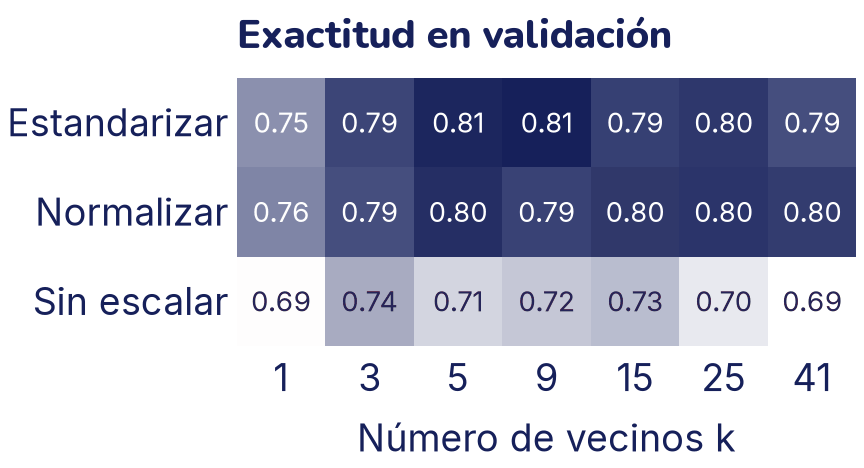

In [ ]:
from sklearn.model_selection import GridSearchCV

rejilla = {
    "modelo__n_neighbors": [1, 3, 5, 9, 15, 25, 41],
    "preparar__num__escalar": [StandardScaler(), MinMaxScaler(),
                               "passthrough"]}
busqueda = GridSearchCV(pipe_knn, rejilla, cv=pliegues)
busqueda.fit(X_ent, y_ent)
for nombre, valor in busqueda.best_params_.items():
    print(f"Mejor {nombre}: {valor}")
print(f"Exactitud en validación: {busqueda.best_score_:.3f}")

# Los 21 puntajes, como tabla: una fila por escalador
tabla = busqueda.cv_results_["mean_test_score"].reshape(7, 3).T
escaladores = ["Estandarizar", "Normalizar", "Sin escalar"]
ks = rejilla["modelo__n_neighbors"]
fig, ax = plt.subplots(figsize=(4.8, 2.6))
sns.heatmap(tabla, annot=True, fmt=".2f", cmap=blanco_tinta,
            cbar=False, xticklabels=ks, yticklabels=escaladores,
            annot_kws={"fontsize": 11}, ax=ax)
ax.tick_params(axis="y", labelrotation=0)
ax.set_xlabel("Número de vecinos k")
ax.set_title("Exactitud en validación")
plt.show()

El mapa cuenta dos historias. Por filas: escalar (de cualquiera de las dos formas) le gana a no escalar con todos los valores de *k*. Por columnas: con *k* = 1 el modelo memoriza el ruido, y desde 3 o 5 vecinos la exactitud ronda el 0,80 sin grandes cambios. Las diferencias entre las casillas oscuras son de un punto o dos, del mismo tamaño que el vaivén entre pliegues: no te tomes al pie de la letra cuál ganó.

La rejilla tiene un problema: el número de combinaciones se multiplica. Con 4 hiperparámetros de 10 valores cada uno serían 10 000 combinaciones, cada una con 5 entrenamientos. `RandomizedSearchCV` prueba en cambio un número fijo de combinaciones **al azar**, sacadas de las distribuciones que le das. Con el mismo presupuesto explora más valores distintos de cada hiperparámetro, y suele encontrar algo igual de bueno mucho antes. Para *C*, que puede ir de 0,001 a 100, conviene sortear en escala logarítmica (`loguniform`), para que cada orden de magnitud (cada salto de 10 veces) tenga la misma oportunidad: que entre 0,001 y 0,01 se sortee tanto como entre 10 y 100.

In [ ]:
from scipy.stats import loguniform
from sklearn.model_selection import RandomizedSearchCV

pipe_log = pipe_logistica(numericas + ["es_nino"])
distribuciones = {"modelo__C": loguniform(1e-3, 1e2)}
azar = RandomizedSearchCV(pipe_log, distribuciones, n_iter=20,
                          cv=pliegues, random_state=0)
azar.fit(X_ent_mas, y_ent)
print(f"Mejor C: {azar.best_params_['modelo__C']:.3f}")
print(f"Exactitud en validación: {azar.best_score_:.3f}")

Mejor C: 0.441
Exactitud en validación: 0.822


`random_state=0` fija el sorteo, para que la búsqueda dé lo mismo cada vez que la corras. Un último cuidado: el mejor puntaje de una búsqueda es un poco optimista, porque elegimos la combinación que mejor salió entre muchas, y parte de su ventaja es suerte. Por eso el conjunto de prueba sigue guardado: es el único número que no usamos para decidir nada.

## El pipeline del tema 10

Juntemos todo en un solo bloque que puedas copiar y reutilizar. Va desde la tabla cruda hasta la evaluación final, y deja listas tres piezas con nombre: `agregar_variables`, `crear_pipeline_titanic(modelo)` y la división `X_ent`, `X_prueba`, `y_ent`, `y_prueba`. Te sirven para los ejercicios de este tema; en el tema 11 vas a armar una versión parecida y más sencilla, sin las variables nuevas y sin escalar.

In [ ]:
# El pipeline del tema 10: el Titanic, de la tabla cruda a la predicción
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

NUMERICAS = ["pclass", "age", "sibsp", "parch", "fare",
             "familia", "tarifa_persona", "es_nino"]
CATEGORICAS = ["sex", "embarked"]

def agregar_variables(df):
    """Agrega variables nuevas calculadas fila por fila."""
    df = df.copy()
    df["familia"] = df["sibsp"] + df["parch"] + 1
    df["tarifa_persona"] = df["fare"] / df["familia"]
    df["es_nino"] = (df["age"] < 12).astype(int)
    return df

def crear_pipeline_titanic(modelo):
    """Prepara las columnas del Titanic y termina en el modelo dado."""
    numericas = Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler())])
    categoricas = Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    preparar = ColumnTransformer([
        ("num", numericas, NUMERICAS),
        ("cat", categoricas, CATEGORICAS)])
    return Pipeline([("preparar", preparar), ("modelo", modelo)])

titanic = agregar_variables(sns.load_dataset("titanic"))
X = titanic[NUMERICAS + CATEGORICAS]
y = titanic["survived"]
X_ent, X_prueba, y_ent, y_prueba = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=0)

pipeline_titanic = crear_pipeline_titanic(
    LogisticRegression(C=0.44, max_iter=1000))
pipeline_titanic.fit(X_ent, y_ent)

# La prueba se usa una sola vez, al final
pred = pipeline_titanic.predict(X_prueba)
exactitud = pipeline_titanic.score(X_prueba, y_prueba)
print(f"Exactitud en prueba: {exactitud:.3f}")
print(classification_report(y_prueba, pred,
                            target_names=["murió", "sobrevivió"]))

Exactitud en prueba: 0.785
              precision    recall  f1-score   support

       murió       0.80      0.87      0.83       137
  sobrevivió       0.76      0.65      0.70        86

    accuracy                           0.78       223
   macro avg       0.78      0.76      0.77       223
weighted avg       0.78      0.78      0.78       223


Dos detalles. El modelo final usa todas las variables nuevas (las que no ayudaron tampoco estorban a la regresión logística) y una *C* redondeada cerca de la que encontró la búsqueda aleatoria. La exactitud en prueba, 0,785, queda unos 4 puntos por debajo del 0,822 de la validación. Es una diferencia normal: el mejor puntaje de una búsqueda es algo optimista, y con solo 223 pasajeros cada uno vale casi medio punto, así que la prueba también tiene su propio vaivén. Lo que importa es que este número no se usó para elegir nada. El informe con la precisión y la exhaustividad de cada clase es el del tema 9: el modelo reconoce mejor a los que murieron que a los que sobrevivieron.

Como el pipeline es un solo objeto, predecir para un pasajero nuevo, con huecos y todo, es una línea:

In [ ]:
nuevo = agregar_variables(pd.DataFrame([{
    "pclass": 3, "sex": "female", "age": np.nan, "sibsp": 0,
    "parch": 2, "fare": 15.0, "embarked": "S"}]))
prob = pipeline_titanic.predict_proba(nuevo[NUMERICAS + CATEGORICAS])
print(f"Probabilidad de sobrevivir: {prob[0, 1]:.2f}")

Probabilidad de sobrevivir: 0.54


A esta pasajera le falta la edad, y el pipeline la rellena con la mediana que aprendió del entrenamiento, escala, codifica y predice, todo en el mismo orden en que lo hizo al entrenar.

## Lo que aprendiste y lo que sigue

- Los datos reales llegan con **faltantes**, **texto** y **escalas distintas**. Se mira primero qué falta (el mapa de faltantes) y qué columnas sobran o hacen trampa.
- **Imputar** rellena los huecos: la **mediana** si la columna es asimétrica, la **media** si es simétrica, la **más frecuente** para el texto.
- **One-hot** convierte una variable nominal en columnas de 0 y 1, sin inventar un orden. **Estandarizar** y **normalizar** ponen las numéricas en escalas parecidas; no cambian la forma de la distribución.
- **Fuga de datos**: todo paso que aprende de los datos es parte del modelo y se ajusta solo con el entrenamiento. Preparar con la prueba infla el puntaje, a veces un poco y a veces muchísimo.
- Un **`Pipeline`** con un **`ColumnTransformer`** encadena la preparación y el modelo en un solo objeto, que la validación cruzada y la búsqueda reentrenan entero en cada pliegue.
- Los **hiperparámetros** se eligen con **`GridSearchCV`** (todas las combinaciones) o **`RandomizedSearchCV`** (combinaciones al azar), siempre con validación cruzada sobre el entrenamiento.
- Una **variable nueva** se queda solo si mejora más que el vaivén entre pliegues.

En el tema 11 vas a cambiar la regresión logística por árboles de decisión y bosques, con una preparación parecida a esta pero más sencilla: los árboles no necesitan escalar.

# Ejercicios

## Antes de empezar

Varios ejercicios usan lo que dejó la teoría: el bloque final, «El pipeline del tema 10» (`agregar_variables`, `crear_pipeline_titanic`, `NUMERICAS`, `CATEGORICAS`, `titanic` con las variables nuevas y la división `X_ent`, `X_prueba`, `y_ent`, `y_prueba`), y también `pliegues`, `prep_numericas` y `prep_categoricas`. En este cuaderno, ejecuta las celdas de la teoría y trabaja en los ejercicios, que vienen debajo. Intenta cada ejercicio antes de abrir la respuesta.

## Ejercicios

### 1. ¿Por qué falta?

Para cada caso, di si el dato falta al azar, por algo que sí vemos en otra columna, o por el propio valor que falta. Después piensa qué problema traería rellenarlo con la mediana.

1. Una encuesta de ingresos en la que las familias con ingresos más altos dejan la pregunta en blanco más seguido.
2. Un registro de notas en el que se mojó una hoja y se perdieron las notas de diez estudiantes, sin importar quiénes eran.
3. Una base de pacientes donde a los que llegaron de noche no se les midió la presión, porque el aparato estaba en otra sala. La hora de llegada sí está anotada.

<details>
<summary>Respuesta</summary>

1. **Por el propio valor**: los que faltan son justamente los ingresos altos. Rellenar con la mediana los convierte en ingresos normales y el promedio de la encuesta queda más bajo que el real. Ningún relleno lo arregla del todo; al menos conviene marcar con una columna aparte (`add_indicator=True`) que el dato faltaba, porque eso ya es información.
2. **Al azar**: que falte no dice nada del estudiante. Rellenar con la mediana es razonable; solo hace la columna un poco más «picuda».
3. **Por algo que sí vemos**: depende de la hora de llegada. Si los pacientes de la noche son distintos (por ejemplo, llegan más graves), rellenar con la mediana de todos los hace parecer más sanos. Una mejora es rellenar con la mediana de los pacientes de su mismo turno, siempre calculada solo con el entrenamiento.

</details>

### 2. ¿Media o mediana?

Los sueldos mensuales de seis personas de una oficina (datos inventados) son 3000, 3200, 3500, 3800, 4000 y 45 000 bolivianos. A una séptima persona le falta el sueldo. Calcula la media y la mediana sin computadora, decide con cuál rellenarías y comprueba con `SimpleImputer`.

<details>
<summary>Respuesta</summary>

- Media: (3000 + 3200 + 3500 + 3800 + 4000 + 45 000) / 6 = 62 500 / 6 ≈ **10 417** Bs.
- Mediana: con seis valores ordenados, el promedio de los dos del medio, (3500 + 3800) / 2 = **3650** Bs.

Rellenaría con la **mediana**. El sueldo de 45 000 (quizás el del jefe) arrastra la media hasta casi el triple de lo que gana cualquiera de los otros cinco: la media no describe a nadie de la oficina.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
sueldos = pd.DataFrame(
    {"sueldo": [3000, 3200, 3500, 3800, 4000, 45000, np.nan]})
for estrategia in ["mean", "median"]:
    imp = SimpleImputer(strategy=estrategia).fit(sueldos)
    relleno = imp.transform(sueldos)[-1, 0]
    print(f"{estrategia:6}: rellena con {relleno:.0f}")

<details>
<summary>Respuesta (sigue)</summary>

`SimpleImputer` ignora el faltante al calcular, como hiciste a mano.

</details>

### 3. ¿One-hot o número?

Di cómo convertirías cada columna en números y por qué:

1. El departamento de Bolivia donde vive cada estudiante.
2. La talla de una polera: S, M, L o XL.
3. El color favorito.
4. El curso: de 1.º a 6.º de secundaria.

<details>
<summary>Respuesta</summary>

1. **One-hot**: los departamentos no tienen orden. Numerarlos de 1 a 9 diría, por ejemplo, que Pando está «más lejos» de La Paz que Oruro solo por el número que les tocó. Son 9 columnas nuevas.
2. **Número**: S, M, L y XL tienen un orden claro (variable **ordinal**), así que 1, 2, 3 y 4 respetan algo real. One-hot también funcionaría, pero perdería ese orden.
3. **One-hot**: nominal, sin orden.
4. **Número**: es ordinal y además los pasos son parejos (de un curso al siguiente hay un año), así que 1 a 6 funciona muy bien.

</details>

### 4. Estandarizar y normalizar a mano

Para los valores 2, 4, 6, 8 y 30:

1. Calcula la media y la desviación estándar (divide por 5, como `StandardScaler`), y estandariza.
2. Normaliza al rango de 0 a 1.
3. ¿Cómo quedan repartidos los cuatro primeros valores en cada caso? Compruébalo con scikit-learn.

<details>
<summary>Respuesta</summary>

1. Media = 50 / 5 = 10. Las diferencias con la media son −8, −6, −4, −2 y 20; sus cuadrados suman 64 + 36 + 16 + 4 + 400 = 520, la varianza es 520 / 5 = 104 y la desviación √104 ≈ 10,2. Estandarizados: −0,78, −0,59, −0,39, −0,20 y 1,96.
2. Mínimo 2 y máximo 30, así que se divide por 28: 0, 0,07, 0,14, 0,21 y 1.
3. Con la normalización, los cuatro primeros quedan apretados entre 0 y 0,21: el 30, un atípico, se queda con casi todo el rango. Con la estandarización también quedan juntos, pero al menos centrados cerca de 0 y sin un techo fijo.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
v = np.array([[2], [4], [6], [8], [30]])
print("Estandarizados:", StandardScaler().fit_transform(v).ravel().round(2))
print("Normalizados:  ", MinMaxScaler().fit_transform(v).ravel().round(2))

### 5. Encuentra la fuga: escalar primero

Una compañera escribió esto para medir los vecinos cercanos en el Titanic. ¿Dónde está la fuga? Corrígelo.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

datos = titanic[["pclass", "age", "sibsp", "parch", "fare"]]
datos = datos.fillna(datos.median())
datos = (datos - datos.mean()) / datos.std()
D_ent, D_prueba, d_ent, d_prueba = train_test_split(
    datos, titanic["survived"], test_size=0.25,
    stratify=titanic["survived"], random_state=0)
knn = KNeighborsClassifier(n_neighbors=5).fit(D_ent, d_ent)
print(f"Exactitud: {knn.score(D_prueba, d_prueba):.3f}")

Exactitud: 0.704


<details>
<summary>Respuesta</summary>

La mediana con que rellena y la media y la desviación con que estandariza se calculan con **todos** los pasajeros, incluidos los de prueba, y recién después divide. La prueba influyó en la preparación. La corrección es dividir primero y meter la preparación en un pipeline, que la ajusta solo con el entrenamiento:

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
columnas_num = ["pclass", "age", "sibsp", "parch", "fare"]
knn_bien = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", StandardScaler()),
    ("modelo", KNeighborsClassifier(n_neighbors=5))])
knn_bien.fit(X_ent[columnas_num], y_ent)
exactitud = knn_bien.score(X_prueba[columnas_num], y_prueba)
print(f"Exactitud: {exactitud:.3f}")

<details>
<summary>Respuesta (sigue)</summary>

Esta vez la diferencia es chica (y hasta a favor de la versión correcta), como viste en la teoría: con 891 pasajeros, una mediana y una media casi no cambian. Pero la primera versión no es confiable por cómo está hecha, no por el número que dio, y el mismo hábito con un paso que mira la respuesta infla el puntaje muchísimo.

</details>

### 6. Encuentra la fuga: una columna sospechosa

Otro estudiante quiso usar «todas las columnas que sirvan» y obtuvo un modelo casi perfecto. ¿Qué pasó?

In [ ]:
cols_todas = ["pclass", "sex", "age", "fare", "embarked", "alive"]
T_ent, T_prueba, t_ent, t_prueba = train_test_split(
    titanic[cols_todas], titanic["survived"], test_size=0.25,
    stratify=titanic["survived"], random_state=0)
prep_todas = ColumnTransformer([
    ("num", prep_numericas, ["pclass", "age", "fare"]),
    ("cat", prep_categoricas, ["sex", "embarked", "alive"])])
sospechoso = Pipeline([("preparar", prep_todas),
                       ("modelo", LogisticRegression(max_iter=1000))])
sospechoso.fit(T_ent, t_ent)
print(f"Exactitud: {sospechoso.score(T_prueba, t_prueba):.3f}")

Exactitud: 1.000


<details>
<summary>Respuesta</summary>

La columna `alive` es la respuesta escrita con palabras: vale `"yes"` exactamente cuando `survived` vale 1. El modelo no aprendió nada del Titanic, solo a leer la respuesta en otra columna. Se comprueba en una línea:

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
print(pd.crosstab(titanic["alive"], titanic["survived"]))

<details>
<summary>Respuesta (sigue)</summary>

Esta es la **fuga por la respuesta** (en inglés, *target leakage*): una columna que en la vida real no conocerías al momento de predecir, porque se anota después o es una copia de lo que quieres predecir. Pasa también con columnas menos obvias, como «días de internación» para predecir si un paciente va a necesitar internación. **Un resultado demasiado bueno para ser cierto casi siempre es una fuga.** La corrección es sacar `alive` de las columnas.

</details>

### 7. Encuentra la fuga: elegir con la prueba

Este código busca el mejor número de vecinos. ¿Por qué el 0,816 que imprime al final no es una buena estimación de cómo le irá al modelo con pasajeros nuevos?

In [ ]:
mejor_k, mejor_puntaje = None, 0
for k in [1, 3, 5, 9, 15, 25, 41]:
    m = crear_pipeline_titanic(KNeighborsClassifier(n_neighbors=k))
    puntaje = m.fit(X_ent, y_ent).score(X_prueba, y_prueba)
    if puntaje > mejor_puntaje:
        mejor_k, mejor_puntaje = k, puntaje
print(f"Mejor k = {mejor_k}, exactitud = {mejor_puntaje:.3f}")

Mejor k = 5, exactitud = 0.816


<details>
<summary>Respuesta</summary>

El pipeline está bien armado, pero el conjunto de prueba se usó para **elegir** *k*: se probaron siete modelos y se quedó el que mejor salió en la prueba. Parte de esa ventaja es suerte con esos 223 pasajeros, así que el 0,816 es optimista. Es la fuga del tema 7: la prueba se usa una sola vez, al final. La corrección es elegir *k* con validación cruzada sobre el entrenamiento y recién después mirar la prueba:

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
buscar_k = GridSearchCV(
    crear_pipeline_titanic(KNeighborsClassifier()),
    {"modelo__n_neighbors": [1, 3, 5, 9, 15, 25, 41]}, cv=pliegues)
buscar_k.fit(X_ent, y_ent)
print("k elegido con validación:", buscar_k.best_params_)
print(f"Validación: {buscar_k.best_score_:.3f}"
      f"   prueba: {buscar_k.score(X_prueba, y_prueba):.3f}")

<details>
<summary>Respuesta (sigue)</summary>

La validación elige otro *k*, y la prueba, usada una sola vez, da un número honesto. Que el número honesto sea más bajo no es un error: es la verdad que el primer código escondía.

</details>

### 8. Escribe un pipeline completo

Arma desde cero, sin copiar `crear_pipeline_titanic`, un pipeline para el Titanic que:

1. use las columnas `pclass`, `sex`, `age`, `sibsp`, `parch`, `fare`, `embarked` y además `deck`;
2. impute la edad con la mediana y agregue una columna que diga si faltaba;
3. rellene la cubierta faltante con el texto `"sin dato"` (`strategy="constant"`), porque que falte puede decir algo (los pasajeros de tercera casi nunca tienen cubierta anotada);
4. termine en una regresión logística.

Mide su exactitud con validación cruzada en el entrenamiento y compárala con la de `crear_pipeline_titanic(LogisticRegression(max_iter=1000))`.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
X_deck = agregar_variables(titanic)[
    ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked",
     "deck"]]
# Las mismas filas de entrenamiento que en la teoría
Xd_ent = X_deck.loc[X_ent.index]
# deck es de tipo categoría; como texto, admite el relleno nuevo
Xd_ent = Xd_ent.astype({"deck": "object"})

mi_prep = ColumnTransformer([
    ("edad", Pipeline([
        ("imputar", SimpleImputer(strategy="median",
                                  add_indicator=True)),
        ("escalar", StandardScaler())]), ["age"]),
    ("num", Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler())]),
     ["pclass", "sibsp", "parch", "fare"]),
    ("cubierta", Pipeline([
        ("imputar", SimpleImputer(strategy="constant",
                                  fill_value="sin dato")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))]), ["deck"]),
    ("cat", Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))]),
     ["sex", "embarked"])])
mi_pipe = Pipeline([("preparar", mi_prep),
                    ("modelo", LogisticRegression(max_iter=1000))])

mio = cross_val_score(mi_pipe, Xd_ent, y_ent, cv=pliegues)
tema = cross_val_score(
    crear_pipeline_titanic(LogisticRegression(max_iter=1000)),
    X_ent, y_ent, cv=pliegues)
print(f"Con deck e indicador: {mio.mean():.3f} ± {mio.std():.3f}")
print(f"Pipeline del tema:    {tema.mean():.3f} ± {tema.std():.3f}")
print(mi_pipe.fit(Xd_ent, y_ent).named_steps["preparar"]
      .get_feature_names_out()[:4])

<details>
<summary>Respuesta</summary>

Fíjate en tres cosas: el indicador aparece como una columna más (`edad__missingindicator_age`); `strategy="constant"` convierte el faltante en una categoría más, que one-hot trata como cualquier otra; y la cubierta no mejoró la validación. Con la clase del pasaje ya en el modelo, saber si falta la cubierta agrega poco: los dos datos cuentan casi la misma historia.

</details>

### 9. Resúmenes estadísticos

Una fábrica (datos **sintéticos**) registra 50 lecturas de vibración de cada máquina. Las máquinas sanas vibran parejo; las que van a fallar tienen la misma vibración promedio, pero con sacudones de vez en cuando. Cada fila es una máquina y cada columna, una lectura.

In [ ]:
rng = np.random.default_rng(1)
n_maquinas = 400
falla = rng.integers(0, 2, size=n_maquinas)
lecturas = rng.normal(0, 1, size=(n_maquinas, 50))
# Las que fallan: algunos sacudones fuertes, en momentos al azar
sacudon = rng.random((n_maquinas, 50)) < 0.06
lecturas = lecturas + falla[:, None] * sacudon * rng.normal(
    0, 4, size=(n_maquinas, 50))
print(lecturas.shape, "  fallan:", falla.sum())

(400, 50)   fallan: 205


1. Mide con validación cruzada una regresión logística que usa las 50 lecturas tal cual.
2. Crea, para cada máquina, cuatro variables: la media, la desviación estándar, el máximo del valor absoluto y la curtosis (`scipy.stats.kurtosis`, que mide qué tan «picuda» o con colas largas es una distribución). Mide el mismo modelo con esas cuatro.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
from scipy.stats import kurtosis

modelo_l = Pipeline([
    ("escalar", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=1000))])

crudas = cross_val_score(modelo_l, lecturas, falla, cv=pliegues)

resumenes = np.column_stack([
    lecturas.mean(axis=1),
    lecturas.std(axis=1),
    np.abs(lecturas).max(axis=1),
    kurtosis(lecturas, axis=1)])
resumidas = cross_val_score(modelo_l, resumenes, falla, cv=pliegues)
print(f"50 lecturas crudas:    {crudas.mean():.3f}")
print(f"4 resúmenes por fila:  {resumidas.mean():.3f}")

<details>
<summary>Respuesta</summary>

Con las lecturas crudas, el modelo no aprende nada (acierta como una moneda): un sacudón puede caer en cualquier columna, y para la regresión logística cada columna es una variable distinta con su propio peso. Los resúmenes estadísticos describen **la forma** de las 50 lecturas sin importar en qué momento pasó cada sacudón, y con eso el modelo acierta el 84 %, contra el 50 % de las lecturas crudas. Calcularlos no produce fuga: cada fila usa solo sus propias lecturas.

</details>

### 10. ¿Cuánto cuesta una búsqueda?

Quieres buscar con `GridSearchCV` y validación cruzada de 5 pliegues sobre: *C* en 6 valores, la estrategia de imputación de la edad en 2 valores (`"mean"`, `"median"`) y el escalador en 3 opciones. ¿Cuántos modelos se entrenan? ¿Y con `RandomizedSearchCV(n_iter=10)`? Compruébalo con `ParameterGrid`.

<details>
<summary>Respuesta</summary>

La rejilla tiene 6 × 2 × 3 = 36 combinaciones; con 5 pliegues son 36 × 5 = **180** entrenamientos, más uno final con todo el entrenamiento y la mejor combinación (`refit`). La búsqueda aleatoria con `n_iter=10` hace 10 × 5 = **50**, más el final.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
from sklearn.model_selection import ParameterGrid

rejilla_grande = {
    "modelo__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "preparar__num__imputar__strategy": ["mean", "median"],
    "preparar__num__escalar": [StandardScaler(), MinMaxScaler(),
                               "passthrough"]}
combinaciones = len(ParameterGrid(rejilla_grande))
print("Combinaciones:", combinaciones,
      "  entrenamientos:", combinaciones * 5 + 1)

<details>
<summary>Respuesta (sigue)</summary>

Cada hiperparámetro nuevo **multiplica** el costo de la rejilla. Por eso, cuando hay más de dos o tres, conviene la búsqueda aleatoria.

</details>

## Mini-proyecto: del CSV sucio a la predicción

En el tema 4 conociste los pingüinos de Palmer. Ahora vas a predecir el **sexo** de cada pingüino a partir de sus medidas, su especie y su isla, con todo el proceso en un solo `Pipeline`.

1. **Del CSV a la tabla.** Guarda el dataset en un CSV y vuelve a leerlo, como si te lo hubieran mandado:

   ```python
   sns.load_dataset("penguins").to_csv("pinguinos.csv", index=False)
   pinguinos = pd.read_csv("pinguinos.csv")
   ```

2. **Mira qué falta.** Cuenta los faltantes por columna. Las filas sin sexo no sirven para entrenar ni para evaluar (no se puede imputar la respuesta): sácalas. Las demás faltas, déjalas para el pipeline.
3. **Divide primero**, con 25 % para prueba, estratificando por sexo y con `random_state=0`.
4. **Arma el pipeline**: las cuatro medidas imputadas con la mediana y estandarizadas, `species` e `island` imputadas con la más frecuente y en one-hot, y al final un modelo.
5. **Busca hiperparámetros** con `GridSearchCV` para dos modelos: regresión logística (*C* entre 0,01 y 100) y vecinos cercanos (*k* entre 1 y 25). Quédate con el que tenga mejor validación.
6. **Evalúa una sola vez** en la prueba, con `classification_report` y la matriz de confusión del tema 9.
7. **Informe.** En cinco líneas: qué hiciste con los faltantes, qué modelo ganó y con qué hiperparámetros, la exactitud en validación y en prueba, y una advertencia (¿sirve este modelo para pingüinos de otras islas o especies?).

In [ ]:
# @title Resultados de referencia, para comprobar los tuyos: código (doble clic para verlo)
from sklearn.metrics import confusion_matrix

sns.load_dataset("penguins").to_csv("pinguinos.csv", index=False)
pinguinos = pd.read_csv("pinguinos.csv")
print(pinguinos.isna().sum().to_string())
pinguinos = pinguinos.dropna(subset=["sex"])
print("Filas con sexo:", len(pinguinos))

medidas = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm",
           "body_mass_g"]
P = pinguinos[medidas + ["species", "island"]]
s = pinguinos["sex"]
P_ent, P_prueba, s_ent, s_prueba = train_test_split(
    P, s, test_size=0.25, stratify=s, random_state=0)

prep_ping = ColumnTransformer([
    ("num", prep_numericas, medidas),
    ("cat", prep_categoricas, ["species", "island"])])
candidatos = {
    "logística": (LogisticRegression(max_iter=1000),
                  {"modelo__C": [0.01, 0.1, 1, 10, 100]}),
    "vecinos": (KNeighborsClassifier(),
                {"modelo__n_neighbors": [1, 3, 5, 9, 15, 25]})}
mejores = {}
for nombre, (modelo, rejilla) in candidatos.items():
    pipe = Pipeline([("preparar", prep_ping), ("modelo", modelo)])
    b = GridSearchCV(pipe, rejilla, cv=pliegues).fit(P_ent, s_ent)
    mejores[nombre] = b
    print(f"{nombre:10} {b.best_params_}  validación = "
          f"{b.best_score_:.3f}")

ganador = max(mejores.values(), key=lambda b: b.best_score_)
pred = ganador.predict(P_prueba)
print(f"Prueba: {ganador.score(P_prueba, s_prueba):.3f}")
print(confusion_matrix(s_prueba, pred))
print(classification_report(s_prueba, pred))

<details>
<summary>Resultados de referencia, para comprobar los tuyos</summary>

- **Faltantes**: 11 pingüinos sin sexo (se sacan: es la respuesta) y 2 sin medidas. Esos dos también tienen el sexo vacío, así que al sacar las 11 filas ya no queda ningún faltante; el imputador del pipeline igual queda listo por si llega un pingüino incompleto.
- **Ganador**: la regresión logística con *C* = 10, con 91,1 % en validación, casi empatada con los vecinos cercanos (*k* = 5, 90,8 %): una diferencia así no permite decir que un modelo sea mejor que el otro. En prueba acierta el 90,5 %, muy parecido a la validación, y se equivoca por igual con hembras y machos (4 de 42 en cada grupo). Con solo 84 pingüinos de prueba, cada uno vale más de un punto.
- **Advertencia**: el modelo vio tres especies de tres islas de la Antártida. Con otra especie, de otro tamaño, las medidas que separan machos de hembras serían otras.

</details>

## Errores comunes

- **Preparar antes de dividir.** Imputar, escalar, elegir columnas o codificar con todos los datos mete información de la prueba en el entrenamiento. Divide primero y pon cada paso dentro del pipeline.
- **Llamar a `fit` sobre la prueba.** El imputador y el escalador se ajustan una sola vez, con el entrenamiento; a la prueba solo se le aplica `transform`. Con un pipeline, esto ocurre solo.
- **Dejar una columna que contiene la respuesta.** `alive` en el Titanic, una fecha de alta en datos de hospital. Si el modelo es casi perfecto, sospecha.
- **Elegir hiperparámetros mirando la prueba.** Para elegir está la validación cruzada; la prueba se usa una vez, al final.
- **Numerar categorías sin orden.** S = 0, C = 1, Q = 2 inventa un orden y unas distancias que no existen. Usa one-hot para las nominales.
- **Rellenar con la media una columna con atípicos.** Unos pocos valores enormes arrastran la media. La mediana es la opción segura por defecto.
- **Imputar la respuesta.** Las filas sin respuesta no sirven para entrenar ni para evaluar: se sacan.
- **Olvidar escalar antes de los vecinos cercanos o de un descenso de gradiente.** La variable con números grandes manda. Los árboles del tema 11 son la excepción.
- **Quedarse con una variable nueva por una mejora menor que el vaivén entre pliegues.** Mira el ± antes de celebrar.
- **No fijar semillas.** Sin `random_state` en la división, los pliegues y la búsqueda aleatoria, cada corrida da otro número y no puedes comparar.

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Imputar faltantes con la media o la mediana y justificar la elección (ejercicios 1 y 2, paso 2 del mini-proyecto).
- Codificar variables categóricas con one-hot y escalar las numéricas, estandarizando o normalizando (ejercicios 3 y 4).
- Armar un `Pipeline` con `ColumnTransformer` y reconocer la fuga de datos (ejercicios 5, 6, 7 y 8, y pasos 3 y 4 del mini-proyecto).
- Buscar hiperparámetros con `GridSearchCV` y `RandomizedSearchCV` (ejercicios 7 y 10, paso 5 del mini-proyecto).
- Crear variables nuevas, como conteos, cocientes y resúmenes estadísticos, y medir si ayudan (ejercicios 8 y 9).